Integrantes:
* Gonzalo Andres Valladolid Jimenez
* Daniela Valentina Villacorta Sotelo
* Valentín Tuesta barrantes

c:\Users\valma\Downloads\labo_11_2\.venv\Lib\site-packages\face_recognition_models\__init__.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


13233 imágenes


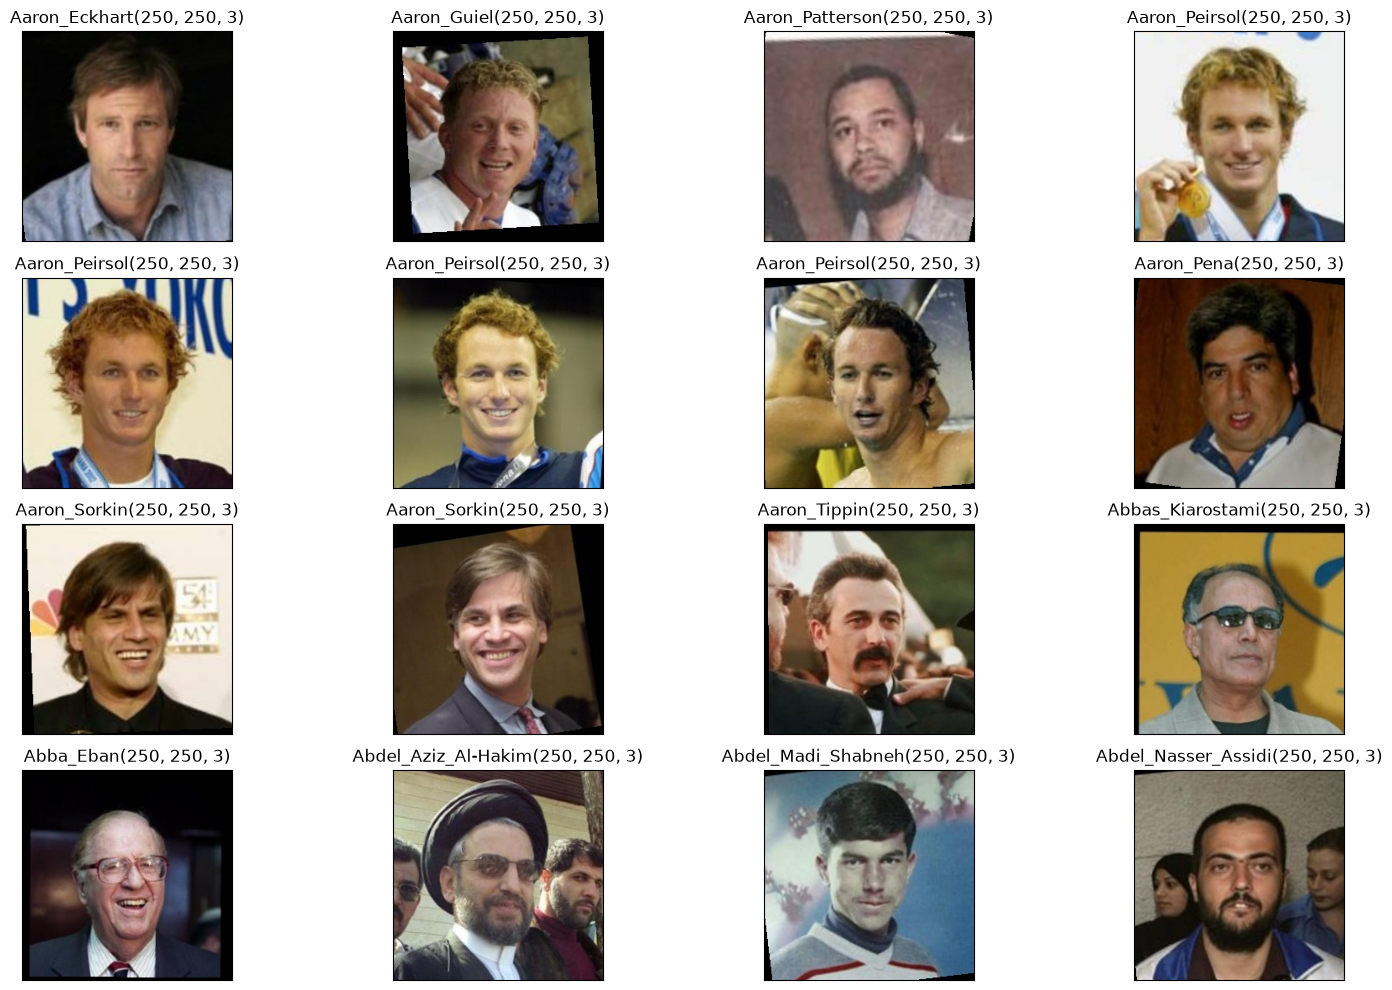

In [1]:
import os, glob, time, statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import face_recognition
import psycopg2
from psycopg2.extras import execute_values
from pgvector.psycopg2 import register_vector
from dotenv import load_dotenv

load_dotenv()

DATASET_PATH = os.getenv("DATASET_PATH") # ajusta a tu ruta
coleccion = pd.DataFrame([
    {"person": os.path.basename(os.path.dirname(p)), "path": p}
    for p in glob.iglob(os.path.join(DATASET_PATH, "**", "*.jpg"), recursive=True)
])
print(len(coleccion), "imágenes")
def mostrarFotos(coleccion, posiciones):
    plt.figure(figsize=(16, 10))
    for i, idx in enumerate(posiciones):
        img = plt.imread(coleccion.path.iloc[idx])
        plt.subplot(4, 4, i + 1)
        plt.imshow(img)
        plt.title(coleccion.person.iloc[idx] + str(img.shape))
        plt.xticks([]); plt.yticks([])
    plt.tight_layout()
    plt.show()
mostrarFotos(coleccion, list(range(16)))

In [2]:
import pickle

def generate_face_embeddings(coleccion, n, print_every=200):

    registros = []

    for i in range(n):
        persona = coleccion.person.iloc[i]
        filename = coleccion.path.iloc[i]

        image = face_recognition.load_image_file(filename)
        encodings = face_recognition.face_encodings(image)  # lista: un vector por rostro detectado

        if encodings:
            embedding = encodings[0]  # tomamos el primer rostro
            registros.append((persona, filename, embedding))

        if (i + 1) % print_every == 0:
            print(f"{i + 1}/{n} imágenes procesadas, {len(registros)} con rostro detectado")

    return registros

if os.path.exists("embeddings.pkl"):
    with open("embeddings.pkl", "rb") as f:
        registros = pickle.load(f)
else:
    registros = generate_face_embeddings(coleccion, n=len(coleccion))
    with open("embeddings.pkl", "wb") as f:
        pickle.dump(registros, f)

print(len(registros), "embeddings")

200/13233 imágenes procesadas, 199 con rostro detectado
400/13233 imágenes procesadas, 399 con rostro detectado
600/13233 imágenes procesadas, 599 con rostro detectado
800/13233 imágenes procesadas, 797 con rostro detectado
1000/13233 imágenes procesadas, 993 con rostro detectado
1200/13233 imágenes procesadas, 1193 con rostro detectado
1400/13233 imágenes procesadas, 1393 con rostro detectado
1600/13233 imágenes procesadas, 1590 con rostro detectado
1800/13233 imágenes procesadas, 1790 con rostro detectado
2000/13233 imágenes procesadas, 1990 con rostro detectado
2200/13233 imágenes procesadas, 2188 con rostro detectado
2400/13233 imágenes procesadas, 2388 con rostro detectado
2600/13233 imágenes procesadas, 2587 con rostro detectado
2800/13233 imágenes procesadas, 2787 con rostro detectado
3000/13233 imágenes procesadas, 2986 con rostro detectado
3200/13233 imágenes procesadas, 3184 con rostro detectado
3400/13233 imágenes procesadas, 3382 con rostro detectado
3600/13233 imágenes pro

In [3]:
import random

fotos_por_persona = pd.Series([r[0] for r in registros]).value_counts()
candidatas = sorted(fotos_por_persona[fotos_por_persona >= 2].index)

random.seed(42)
personas_reservadas = set(random.sample(candidatas, 100))

reservadas, registros_tabla, vistas = [], [], set()
for r in registros:
    if r[0] in personas_reservadas and r[0] not in vistas:
        reservadas.append(r)
        vistas.add(r[0])
    else:
        registros_tabla.append(r)

print(len(reservadas), "consultas reservadas")
print(len(registros_tabla), "registros para insertar en la tabla")

100 consultas reservadas
13076 registros para insertar en la tabla


In [7]:
# P1.3 Almacenamiento en PostgreSQL (credenciales en .env, ver .env.example)
load_dotenv()
conn = psycopg2.connect(host=os.getenv("DB_HOST", "localhost"), port=int(os.getenv("DB_PORT", 5433)),
                        user=os.getenv("DB_USER"), password=os.getenv("DB_PASSWORD"),
                        dbname=os.getenv("DB_NAME"))
conn.autocommit = True
cur = conn.cursor()
cur.execute("CREATE EXTENSION IF NOT EXISTS vector")
register_vector(conn)
cur.execute("""
    CREATE TABLE IF NOT EXISTS face_embeddings (
        id SERIAL PRIMARY KEY,
        name TEXT,
        path TEXT,
        embedding VECTOR(128)
    )""")

# vaciamos antes de insertar para poder re-ejecutar la celda sin duplicar filas
cur.execute("TRUNCATE face_embeddings RESTART IDENTITY")
execute_values(cur, "INSERT INTO face_embeddings (name, path, embedding) VALUES %s",
               registros_tabla)

cur.execute("SELECT COUNT(*) FROM face_embeddings")
print(cur.fetchone()[0], "filas en face_embeddings")

13076 filas en face_embeddings


## P2. Búsqueda kNN lineal y tu doble famoso

In [ ]:
def knn(q, k=10, op="<->"):
    cur.execute(f"SELECT id FROM face_embeddings ORDER BY embedding {op} %s LIMIT %s", (q, k))
    return [r[0] for r in cur.fetchall()]

def knn_lineal(q, k=10, op="<->"):
    cur.execute("SET enable_indexscan = off")  # fuerza Seq Scan: búsqueda lineal, aunque existan índices
    ids = knn(q, k, op)
    cur.execute("RESET enable_indexscan")
    return ids

def tiempo_mediano(f, *args, repeticiones=10):
    tiempos = []
    for _ in range(repeticiones):
        t0 = time.perf_counter()
        f(*args)
        tiempos.append((time.perf_counter() - t0) * 1000)
    return statistics.median(tiempos)

def fotos_por_ids(ids):
    # DataFrame (person, path) en el mismo orden que ids, para usar con mostrarFotos
    cur.execute("SELECT id, name, path FROM face_embeddings WHERE id = ANY(%s)", (ids,))
    filas = {i: (n, p) for i, n, p in cur.fetchall()}
    return pd.DataFrame([{"person": filas[i][0], "path": filas[i][1]} for i in ids])

In [ ]:
# P2a kNN lineal. Consulta: primera imagen reservada (no está en la tabla)
q_persona, q_path, q = reservadas[0]
k = 10
print("Consulta:", q_persona)

resultados = {}
for op, nombre in [("<->", "euclidiana"), ("<=>", "coseno")]:
    ids = knn_lineal(q, k, op)
    t = tiempo_mediano(knn_lineal, q, k, op)
    resultados[nombre] = ids
    print(f"{nombre:10s} mediana {t:.2f} ms -> {list(fotos_por_ids(ids).person)}")

print("Mismo orden:", resultados["euclidiana"] == resultados["coseno"])
print("Mismo conjunto:", set(resultados["euclidiana"]) == set(resultados["coseno"]))

consulta_df = pd.DataFrame([{"person": "CONSULTA " + q_persona, "path": q_path}])
mostrarFotos(pd.concat([consulta_df, fotos_por_ids(resultados["euclidiana"])], ignore_index=True),
             list(range(k + 1)))

In [ ]:
# P2b Tu doble famoso (ruta de la foto en MI_FOTO del .env; por defecto mi_foto.jpg)
def famoso_parecido(q, candidatos=50, top=5):
    cur.execute("""
        SELECT name, MIN(dist) AS dist, COUNT(*) AS fotos
        FROM (SELECT name, embedding <-> %s AS dist
              FROM face_embeddings ORDER BY embedding <-> %s LIMIT %s) t
        GROUP BY name ORDER BY dist LIMIT %s""", (q, q, candidatos, top))
    return cur.fetchall()

def fotos_famosos(q, famosos):
    # foto más parecida de cada famoso, para mostrarla
    filas = []
    for name, dist, fotos in famosos:
        cur.execute("SELECT path FROM face_embeddings WHERE name = %s ORDER BY embedding <-> %s LIMIT 1",
                    (name, q))
        filas.append({"person": f"{name} d={dist:.3f} ", "path": cur.fetchone()[0]})
    return pd.DataFrame(filas)

MI_FOTO = os.getenv("MI_FOTO", "mi_foto.jpg")
mi_foto = None  # el embedding de la foto nunca se inserta en la tabla
if os.path.exists(MI_FOTO):
    mi_foto = face_recognition.face_encodings(face_recognition.load_image_file(MI_FOTO))[0]
    dobles_lineal = famoso_parecido(mi_foto)  # aún no hay índices: búsqueda lineal
    display(pd.DataFrame(dobles_lineal, columns=["name", "dist", "fotos"]))
    yo_df = pd.DataFrame([{"person": "Yo", "path": MI_FOTO}])
    mostrarFotos(pd.concat([yo_df, fotos_famosos(mi_foto, dobles_lineal)], ignore_index=True), list(range(6)))
else:
    print(f"No se encontró {MI_FOTO}: agrega tu foto para buscar tu doble famoso")

## P3. Búsqueda kNN con índices IVFFlat y HNSW

In [ ]:
import re

def borrar_indices():
    cur.execute("DROP INDEX IF EXISTS face_ivf")
    cur.execute("DROP INDEX IF EXISTS face_hnsw")

def crear_ivf(lists=100):
    # deja solo el índice IVFFlat; devuelve el tiempo de construcción en segundos
    borrar_indices()
    t0 = time.perf_counter()
    cur.execute(f"CREATE INDEX face_ivf ON face_embeddings USING ivfflat (embedding vector_l2_ops) WITH (lists = {lists})")
    t = time.perf_counter() - t0
    cur.execute("ANALYZE face_embeddings")
    return t

def crear_hnsw(m=16, ef_construction=64):
    # deja solo el índice HNSW; devuelve el tiempo de construcción en segundos
    borrar_indices()
    t0 = time.perf_counter()
    cur.execute(f"CREATE INDEX face_hnsw ON face_embeddings USING hnsw (embedding vector_l2_ops) "
                f"WITH (m = {m}, ef_construction = {ef_construction})")
    t = time.perf_counter() - t0
    cur.execute("ANALYZE face_embeddings")
    return t

def explain_analyze(q, k=10, op="<->"):
    # devuelve (plan, Execution Time en ms)
    cur.execute(f"EXPLAIN ANALYZE SELECT id FROM face_embeddings ORDER BY embedding {op} %s LIMIT %s", (q, k))
    plan = "\n".join(r[0] for r in cur.fetchall())
    plan = re.sub(r"'\[[^\]]*\]'::vector", "q", plan)  # acorta el vector de 128 dims en el plan
    return plan, float(re.search(r"Execution Time: ([\d.]+) ms", plan).group(1))

def comparar_dobles(nombre_indice):
    if mi_foto is None:
        print("Sin foto: se omite la comparación del doble famoso")
        return
    dobles = famoso_parecido(mi_foto)
    display(pd.DataFrame(dobles, columns=["name", "dist", "fotos"]))
    print(f"{nombre_indice}: mismos 5 famosos que la búsqueda lineal:",
          [d[0] for d in dobles] == [d[0] for d in dobles_lineal])

In [ ]:
# Referencia: búsqueda lineal (Seq Scan)
borrar_indices()
cur.execute("SET enable_indexscan = off")
plan, ms = explain_analyze(q)
cur.execute("RESET enable_indexscan")
print(plan)

In [ ]:
# IVFFlat (solo este índice)
t_build = crear_ivf(lists=100)
cur.execute("SET ivfflat.probes = 10")
print(f"Construcción IVFFlat: {t_build:.2f} s\n")

plan, ms = explain_analyze(q)
print(plan)

ids_ivf = knn(q)
print(f"\nIVFFlat knn(): mediana {tiempo_mediano(knn, q):.2f} ms, "
      f"{len(set(ids_ivf) & set(resultados['euclidiana']))}/10 vecinos iguales a la búsqueda lineal")
comparar_dobles("IVFFlat")

In [ ]:
# HNSW (solo este índice)
t_build = crear_hnsw(m=16, ef_construction=64)
cur.execute("SET hnsw.ef_search = 100")
print(f"Construcción HNSW: {t_build:.2f} s\n")

plan, ms = explain_analyze(q)
print(plan)

ids_hnsw = knn(q)
print(f"\nHNSW knn(): mediana {tiempo_mediano(knn, q):.2f} ms, "
      f"{len(set(ids_hnsw) & set(resultados['euclidiana']))}/10 vecinos iguales a la búsqueda lineal")
comparar_dobles("HNSW")

## P4. Evaluación de resultados
### 1. Efectividad: recall@k

In [ ]:
def recall_at_k(exactos, aproximados):
    return len(set(exactos) & set(aproximados)) / len(exactos)

def evaluar(indice, parametro, valores, exactos, k=10):
    # recall@k promedio y latencia mediana (ms) de knn() sobre las consultas reservadas
    filas = []
    for v in valores:
        cur.execute(f"SET {parametro} = {v}")
        cur.execute("SET enable_seqscan = off")
        recalls, tiempos = [], []
        for (_, _, qq), ex in zip(reservadas, exactos):
            t0 = time.perf_counter()
            ids = knn(qq, k)
            tiempos.append((time.perf_counter() - t0) * 1000)
            recalls.append(recall_at_k(ex, ids))
        cur.execute("RESET enable_seqscan")
        filas.append({"Índice": indice, "Parámetro": f"{parametro.split('.')[1]} = {v}", "valor": v,
                      "recall@10": np.mean(recalls), "Latencia (ms)": statistics.median(tiempos)})
    return filas

exactos = [knn_lineal(qq, 10) for _, _, qq in reservadas]

LISTS = 100
crear_ivf(lists=LISTS)
filas = evaluar("IVFFlat", "ivfflat.probes", [1, 5, 10, 20, LISTS], exactos)
crear_hnsw()
filas += evaluar("HNSW", "hnsw.ef_search", [10, 40, 100, 200], exactos)

tabla_recall = pd.DataFrame(filas)
display(tabla_recall.drop(columns="valor").round(4))

In [ ]:
plt.figure(figsize=(8, 5))
for indice, g in tabla_recall.groupby("Índice"):
    plt.plot(g["Latencia (ms)"], g["recall@10"], marker="o", label=indice)
    for _, r in g.iterrows():
        plt.annotate(str(r["valor"]), (r["Latencia (ms)"], r["recall@10"]),
                     textcoords="offset points", xytext=(5, -10), fontsize=8)
plt.xlabel("Latencia mediana (ms)")
plt.ylabel("recall@10")
plt.title("recall@10 vs. latencia (probes / ef_search)")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### 2. Rendimiento

In [ ]:
def cargar_tabla(regs):
    borrar_indices()
    cur.execute("TRUNCATE face_embeddings RESTART IDENTITY")
    execute_values(cur, "INSERT INTO face_embeddings (name, path, embedding) VALUES %s", regs)
    cur.execute("ANALYZE face_embeddings")

def mediana_explain(consultas, k=10):
    # mediana del Execution Time de EXPLAIN ANALYZE, descartando la primera ejecución
    tiempos = [explain_analyze(qq, k)[1] for qq in consultas]
    return statistics.median(tiempos[1:])

def parametro_minimo(indice, parametro, candidatos, exactos, umbral=0.95):
    # el valor más barato que logra recall@10 >= umbral (o el mayor probado si ninguno lo logra)
    for v in candidatos:
        fila = evaluar(indice, parametro, [v], exactos)[0]
        if fila["recall@10"] >= umbral:
            break
    return v, fila["recall@10"]

def tamano_indice_mb(nombre):
    cur.execute("SELECT pg_relation_size(%s)", (nombre,))
    return cur.fetchone()[0] / 1024 ** 2

consultas_t = [qq for _, _, qq in reservadas[:11]]  # 11 ejecuciones: se descarta la primera
filas = []
for N in [1000, 2000, 4000, 8000, 12000]:
    cargar_tabla(registros_tabla[:N])
    exactos_n = [knn_lineal(qq, 10) for _, _, qq in reservadas]

    cur.execute("SET enable_indexscan = off")
    t_lineal = mediana_explain(consultas_t)
    cur.execute("RESET enable_indexscan")
    filas.append({"N": N, "Método": "Lineal", "Parámetro": "-", "recall@10": 1.0,
                  "Tiempo (ms)": t_lineal, "Construcción (s)": 0.0, "Tamaño índice (MB)": 0.0})

    lists = round(N ** 0.5)
    t_build = crear_ivf(lists)
    candidatos = sorted({v for v in [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30, 40, 50] if v < lists} | {lists})
    probes, rec = parametro_minimo("IVFFlat", "ivfflat.probes", candidatos, exactos_n)
    cur.execute(f"SET ivfflat.probes = {probes}")
    cur.execute("SET enable_seqscan = off")
    t_ivf = mediana_explain(consultas_t)
    cur.execute("RESET enable_seqscan")
    filas.append({"N": N, "Método": "IVFFlat", "Parámetro": f"lists={lists}, probes={probes}", "recall@10": rec,
                  "Tiempo (ms)": t_ivf, "Construcción (s)": t_build, "Tamaño índice (MB)": tamano_indice_mb("face_ivf")})

    t_build = crear_hnsw()
    ef, rec = parametro_minimo("HNSW", "hnsw.ef_search", [10, 20, 30, 40, 60, 80, 100, 150, 200, 300, 400], exactos_n)
    cur.execute(f"SET hnsw.ef_search = {ef}")
    cur.execute("SET enable_seqscan = off")
    t_hnsw = mediana_explain(consultas_t)
    cur.execute("RESET enable_seqscan")
    filas.append({"N": N, "Método": "HNSW", "Parámetro": f"ef_search={ef}", "recall@10": rec,
                  "Tiempo (ms)": t_hnsw, "Construcción (s)": t_build, "Tamaño índice (MB)": tamano_indice_mb("face_hnsw")})
    print(f"N={N}: lineal {t_lineal:.3f} ms, IVFFlat {t_ivf:.3f} ms, HNSW {t_hnsw:.3f} ms")

# dejamos la tabla completa como estaba (sin índices)
cargar_tabla(registros_tabla)

tabla_rendimiento = pd.DataFrame(filas)
display(tabla_rendimiento.round(4))

In [ ]:
plt.figure(figsize=(8, 5))
for metodo, g in tabla_rendimiento.groupby("Método", sort=False):
    plt.plot(g["N"], g["Tiempo (ms)"], marker="o", label=metodo)
plt.xlabel("Tamaño del dataset (N embeddings)")
plt.ylabel("Tiempo de consulta, mediana EXPLAIN ANALYZE (ms)")
plt.title("kNN lineal vs. IVFFlat vs. HNSW (recall@10 ≥ 0,95)")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### 3. Conclusiones (pendiente)
- Ventajas y desventajas de cada método (tiempo de construcción, memoria, recall, parámetros).
- ¿Cómo escalan estas técnicas con datasets de millones de vectores?
- Dos casos reales distintos a reconocimiento facial que se beneficien de una base de datos vectorial.